# Klasifikasi Jenis Kacang Kering (Dry Bean Dataset) Menggunakan Algoritma K-Nearest Neighbor (KNN)

**NAMA  : ANANDA AGUSTINA MULYAWAN**

**NIM   : 241011402253**

**KELAS : 05TPLP021**

### Deskripsi Dataset
Dataset yang digunakan dalam praktikum ini adalah Dry Bean Dataset, yaitu dataset yang berisi data karakteristik fisik biji kacang kering. Dataset ini digunakan untuk mengklasifikasikan jenis kacang berdasarkan ukuran, bentuk, dan karakteristik geometrisnya menggunakan algoritma Machine Learning.
Dataset ini terdiri dari 13.611 baris data dan 17 kolom, yang terdiri dari 16 fitur atau atribut sebagai variabel input dan 1 kolom target bernama Class sebagai penentu jenis kacang.

### Sumber Dataset

Dataset yang digunakan dalam praktikum ini adalah Dry Bean Dataset yang diperoleh dari UCI Machine Learning Repository. Dataset ini berisi 13.611 data biji kacang kering dengan 16 fitur numerik yang menggambarkan karakteristik fisik dan geometris biji kacang, serta satu atribut target untuk mengklasifikasikan tujuh jenis kacang.

Sumber: UCI Machine Learning Repository  
Nama dataset: Dry Bean  
Link: https://archive.ics.uci.edu/dataset/602/dry+bean  
DOI: https://doi.org/10.24432/C50S4B

# 1.Membaca dataset 

import pandas as pd

df = pd.read_excel('Dry_Bean_Dataset.xlsx')

df.head()

### Penjelasan:
- import pandas as pd digunakan untuk memanggil library Pandas yang berfungsi mengolah data berbentuk tabel.
- pd.read_excel() digunakan untuk membaca dataset dari file Excel.
- df merupakan variabel yang menyimpan dataset yang sudah dibaca.
- df.head() digunakan untuk menampilkan lima baris pertama dataset.
Output yang dihasilkan berupa tabel berisi lima data pertama beserta seluruh kolom yang tersedia. Dari output tersebut, kita dapat melihat contoh nilai atribut seperti Area, Perimeter, MajorAxisLength, dan Class.
Fungsi ini membantu memastikan bahwa dataset berhasil dibaca dan struktur datanya sesuai dengan yang dibutuhkan.

# 2. mengetahui jumlah data

In [2]:
print("Jumlah data:", df.shape)

Jumlah data: (13611, 17)


### Penjelasan:
Atribut df.shape digunakan untuk mengetahui jumlah baris dan kolom dalam dataset. Hasilnya ditampilkan dalam bentuk pasangan angka, yaitu jumlah baris terlebih dahulu, kemudian jumlah kolom.

Artinya, dataset memiliki 13.611 baris data dan 17 kolom. Jumlah ini menunjukkan banyaknya sampel yang tersedia untuk proses analisis dan pelatihan model Machine Learning.

# 3.Memeriksa informasi dataset

### A. melihat informasi dataset

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  object 
dtypes: float64(1

### penjelasan
Fungsi df.info() digunakan untuk melihat informasi umum dataset, seperti jumlah baris, nama kolom, jumlah data yang tidak kosong, tipe data, dan penggunaan memori.

Output menunjukkan bahwa dataset mempunyai 13.611 baris dengan 17 kolom. Sebanyak 16 kolom digunakan sebagai atribut numerik, sedangkan kolom Class memiliki tipe data teks atau objek.

Informasi ini penting karena membantu mengetahui tipe data setiap atribut sebelum dilakukan pemrosesan lebih lanjut. Model KNN membutuhkan fitur numerik sehingga kolom target perlu dipisahkan dari fitur input.

## B.melihat nama nama kolom

In [9]:
print("Nama kolom:")
print(df.columns.tolist())

Nama kolom:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']


### Penjelasan:
df.columns digunakan untuk mengambil nama seluruh kolom, sedangkan .tolist() mengubah daftar nama kolom tersebut menjadi list Python agar mudah ditampilkan.

Output menampilkan 17 nama kolom, yaitu 16 atribut karakteristik fisik kacang dan satu kolom Class.

Hasil ini digunakan untuk memastikan bahwa nama atribut sesuai dengan dataset dan membantu menentukan kolom mana yang menjadi fitur serta target klasifikasi.

# 4.MENGECEK MISSING VALUE

### A. MENGECEK DATA KOSONG

In [10]:
print("Jumlah missing value setiap kolom:")
print(df.isnull().sum())

Jumlah missing value setiap kolom:
Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64


### Penjelasan:
- df.isnull() memeriksa apakah terdapat nilai kosong pada setiap sel.
- .sum() menghitung jumlah nilai kosong pada masing-masing kolom.
  
Output menunjukkan bahwa seluruh kolom memiliki nilai kosong sebanyak 0.
Artinya, tidak ditemukan missing value pada dataset. Dengan demikian, berdasarkan pemeriksaan ini, tidak diperlukan penanganan khusus untuk data kosong sebelum melanjutkan proses klasifikasi.

### B. MENGECEK JUMLAH DATA DUPLIKAT

In [11]:
print("Jumlah data duplikat:", df.duplicated().sum())

Jumlah data duplikat: 68


### Penjelasan:
Fungsi df.duplicated() digunakan untuk mendeteksi baris yang memiliki isi sama dengan baris sebelumnya. Kemudian, .sum() menghitung jumlah baris duplikat yang ditemukan.

Artinya, terdapat 68 baris yang teridentifikasi sebagai data duplikat. Pada notebook ini, data tersebut baru diperiksa dan belum dihapus.

Data duplikat perlu diperhatikan karena dapat memengaruhi hasil analisis maupun evaluasi model. Namun, sebelum menghapusnya, sebaiknya dipastikan terlebih dahulu apakah baris tersebut memang merupakan duplikasi yang tidak diperlukan.

# 5. MELIHAT STATISTIK DATASET

In [12]:
df.describe()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000
mean,53048.284549,855.283459,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063
std,29324.095717,214.289696,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36328.000000,703.523500,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703
50%,44652.000000,794.941000,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386
75%,61332.000000,977.213000,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883
max,254616.000000,1985.370000,738.860153,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


### Penjelasan:
Fungsi df.describe() digunakan untuk menampilkan statistik deskriptif dari kolom numerik. Statistik yang ditampilkan meliputi:
- count: jumlah data yang tersedia.
- mean: nilai rata-rata.
- std: standar deviasi atau ukuran penyebaran data.
- min: nilai terkecil.
- 25%: kuartil pertama.
- 50%: median atau nilai tengah.
- 75%: kuartil ketiga.
- max: nilai terbesar.
Berdasarkan output, atribut Area memiliki rata-rata sekitar 53.048,28, dengan nilai minimum 20.420 dan maksimum 254.616.
Hasil tersebut menunjukkan bahwa ukuran biji kacang memiliki variasi yang cukup besar. Statistik deskriptif membantu memahami karakteristik dan rentang nilai data sebelum dilakukan normalisasi.

# 6. Menghitung jumlah setiap jenis kacang

In [13]:
import matplotlib.pyplot as plt

print(df['Class'].value_counts())

Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


### Penjelasan:
Library Matplotlib dipanggil untuk membuat visualisasi, sedangkan df['Class'].value_counts() digunakan untuk menghitung jumlah kemunculan setiap jenis kacang dalam kolom Class.
Output menunjukkan bahwa DERMASON merupakan kelas dengan jumlah data terbanyak, yaitu 3.546, sedangkan BOMBAY merupakan kelas dengan jumlah data paling sedikit, yaitu 522.
Hasil ini digunakan untuk mengetahui distribusi kelas dalam dataset. Informasi tersebut penting karena perbedaan jumlah data antarkelas dapat memengaruhi proses klasifikasi.

# 7.Membuat grafik distribusi kelas

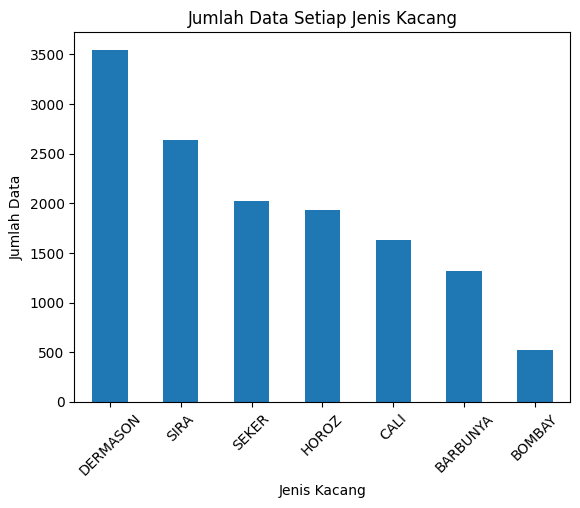

In [14]:
df['Class'].value_counts().plot(kind='bar')

plt.title('Jumlah Data Setiap Jenis Kacang')
plt.xlabel('Jenis Kacang')
plt.ylabel('Jumlah Data')
plt.xticks(rotation=45)
plt.show()

## Penjelasan:
Kode tersebut digunakan untuk menampilkan grafik batang berdasarkan jumlah setiap jenis kacang.
- plot(kind='bar') membuat grafik batang.
- plt.title() memberikan judul grafik.
- plt.xlabel() memberikan nama sumbu horizontal.
- plt.ylabel() memberikan nama sumbu vertikal.
- plt.xticks(rotation=45) memiringkan label kelas sebesar 45 derajat agar lebih mudah dibaca.
- plt.show() menampilkan grafik.
Output berupa grafik batang yang memperlihatkan perbedaan jumlah data pada ketujuh kelas kacang. Batang DERMASON terlihat paling tinggi, sedangkan BOMBAY paling rendah.
Grafik tersebut memudahkan kita memahami distribusi dataset secara visual tanpa harus membaca seluruh angka pada tabel.

# 8.Memisahkan fitur dan target

In [15]:
X = df.drop('Class', axis=1)
y = df['Class']

print("Jumlah fitur:", X.shape[1])
print("Jumlah target:", y.shape[0])

Jumlah fitur: 16
Jumlah target: 13611


### Penjelasan:
Pada tahap ini, dataset dipisahkan menjadi dua bagian.
- X merupakan variabel yang menyimpan 16 fitur numerik.
- y merupakan variabel target yang menyimpan jenis kacang pada kolom Class.
- df.drop('Class', axis=1) menghapus kolom Class dari fitur. Parameter axis=1 berarti operasi dilakukan terhadap kolom.
- X.shape[1] menghitung jumlah fitur.
- y.shape[0] menghitung jumlah label target.

Artinya, model menggunakan 16 atribut sebagai input untuk memprediksi kelas kacang dari 13.611 data yang tersedia.
Pemisahan ini merupakan langkah penting dalam supervised learning karena model harus mempelajari hubungan antara fitur input dan label yang menjadi target prediksi.

# 9.Membagi data training dan testing

In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data training:", X_train.shape)
print("Data testing :", X_test.shape)

Data training: (10888, 16)
Data testing : (2723, 16)


### Penjelasan:
Kode ini menggunakan fungsi train_test_split() dari Scikit-learn untuk membagi dataset menjadi data pelatihan dan data pengujian.
- X_train dan y_train digunakan untuk melatih model.
- X_test dan y_test digunakan untuk menguji kemampuan model dalam memprediksi data yang tidak digunakan pada pelatihan.
- test_size=0.2 berarti 20% data digunakan sebagai data pengujian.
- random_state=42 digunakan agar pembagian data dapat direproduksi.
- stratify=y menjaga proporsi kelas pada data training dan testing agar mendekati distribusi kelas awal.

Artinya, sebanyak 10.888 data digunakan untuk training dan 2.723 data digunakan untuk testing. Jumlah fitur pada kedua bagian tetap 16.
Pembagian ini membantu mengukur kemampuan model dalam mengklasifikasikan data baru, bukan hanya menghafal data yang telah dipelajari.

# 10. Melakukan normalisasi data

In [17]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Normalisasi data berhasil.")

Normalisasi data berhasil.


### Penjelasan:
Normalisasi dilakukan menggunakan StandardScaler untuk menyamakan skala fitur numerik. Metode ini mengubah nilai fitur berdasarkan rata-rata dan standar deviasi data training.
- StandardScaler() membuat objek normalisasi.
- fit_transform(X_train) mempelajari statistik data training sekaligus melakukan normalisasi.
- transform(X_test) menerapkan statistik dari data training pada data testing.

Artinya, proses normalisasi berhasil dilakukan. Tahap ini penting karena KNN menentukan kedekatan berdasarkan jarak. Tanpa normalisasi, fitur yang memiliki nilai numerik besar, seperti Area, dapat lebih mendominasi perhitungan jarak dibandingkan fitur dengan rentang nilai yang kecil.

# 11.Mencari nilai K terbaik

In [18]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

k_values = range(1, 16)
accuracy_values = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    
    y_pred = knn.predict(X_test_scaled)
    accuracy = accuracy_score(y_test, y_pred)
    
    accuracy_values.append(accuracy)

for k, acc in zip(k_values, accuracy_values):
    print(f"K = {k}, Accuracy = {acc:.4f}")

K = 1, Accuracy = 0.8986
K = 2, Accuracy = 0.9016
K = 3, Accuracy = 0.9152
K = 4, Accuracy = 0.9177
K = 5, Accuracy = 0.9166
K = 6, Accuracy = 0.9188
K = 7, Accuracy = 0.9137
K = 8, Accuracy = 0.9137
K = 9, Accuracy = 0.9163
K = 10, Accuracy = 0.9177
K = 11, Accuracy = 0.9185
K = 12, Accuracy = 0.9181
K = 13, Accuracy = 0.9188
K = 14, Accuracy = 0.9199
K = 15, Accuracy = 0.9188


### Penjelasan:
Tahap ini bertujuan mencari nilai K yang menghasilkan akurasi terbaik pada data pengujian.
K merupakan jumlah tetangga terdekat yang dipertimbangkan oleh algoritma KNN ketika menentukan kelas suatu data.
- range(1, 16) menguji nilai K dari 1 sampai 15.
- KNeighborsClassifier(n_neighbors=k) membuat model KNN dengan nilai K tertentu.
- fit() melatih model menggunakan data training.
- predict() memprediksi kelas dari data testing.
- accuracy_score() menghitung proporsi prediksi yang benar.
- accuracy_values.append(acc) menyimpan hasil akurasi setiap nilai K.

Berdasarkan hasil tersebut, nilai K = 14 menghasilkan akurasi tertinggi sebesar 91,99%. Artinya, dari nilai K yang diuji pada rentang 1 sampai 15, K = 14 memberikan hasil klasifikasi terbaik.

# 12. Membuat grafik pengaruh nilai K

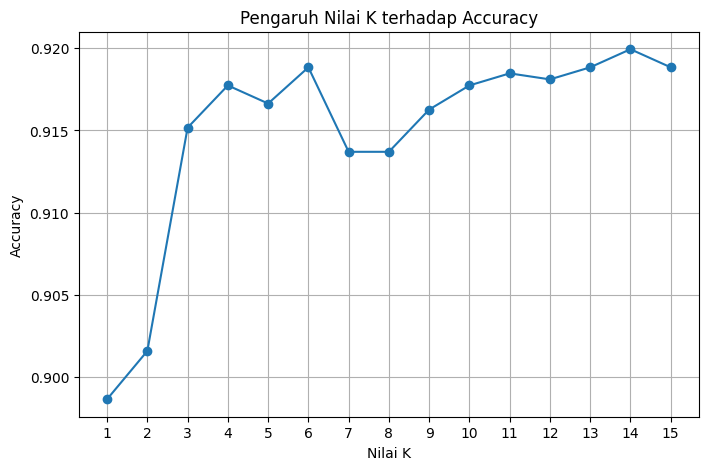

In [19]:
plt.figure(figsize=(8,5))

plt.plot(k_values, accuracy_values, marker='o')

plt.title('Pengaruh Nilai K terhadap Accuracy')
plt.xlabel('Nilai K')
plt.ylabel('Accuracy')
plt.xticks(k_values)
plt.grid()
plt.show()

### Penjelasan:
Kode ini digunakan untuk menampilkan hubungan antara nilai K dan tingkat akurasi model KNN.
- plt.figure(figsize=(8, 5)) menentukan ukuran grafik.
- plt.plot() membuat grafik garis berdasarkan nilai K dan akurasinya.
- marker='o' menampilkan titik pada setiap nilai K.
- plt.xticks(k_values) menampilkan setiap nilai K pada sumbu horizontal.
- plt.grid() menambahkan garis bantu agar grafik lebih mudah dibaca.
- plt.show() menampilkan grafik.
  
Output berupa grafik garis yang menunjukkan bahwa akurasi berubah sesuai dengan nilai K. Akurasi tertinggi berada pada K = 14, kemudian sedikit menurun pada K = 15.
Grafik ini membantu menentukan nilai K yang paling sesuai berdasarkan hasil pengujian.

# 13. MENENTUKAN NILAI K TERBAIK

In [20]:
best_k = k_values[accuracy_values.index(max(accuracy_values))]

print("Nilai K terbaik:", best_k)
print("Accuracy terbaik:", max(accuracy_values))

Nilai K terbaik: 14
Accuracy terbaik: 0.9199412412780023


### Penjelasan:
Kode ini mencari akurasi tertinggi menggunakan max(accuracy_values), kemudian mencari posisi akurasi tersebut dengan .index(). Posisi itu digunakan untuk mengambil nilai K yang sesuai.

Nilai akurasi tersebut setara dengan sekitar 91,99%. Dengan demikian, berdasarkan pengujian yang dilakukan, K = 14 dipilih sebagai nilai K terbaik.

# 14. MEMBUAT MODEL KNN TERBAIK

In [21]:
knn_final = KNeighborsClassifier(n_neighbors=best_k)

knn_final.fit(X_train_scaled, y_train)

print("Model KNN berhasil dibuat.")

Model KNN berhasil dibuat.


### Penjelasan:
Kode ini membuat model KNN menggunakan nilai K terbaik yang sudah ditemukan sebelumnya.
- KNeighborsClassifier(n_neighbors=best_k) membuat model dengan K = 14.
- fit() melatih model menggunakan fitur training yang telah dinormalisasi beserta label kelasnya.

Output tersebut menunjukkan bahwa model telah berhasil dilatih dan siap digunakan untuk memprediksi kelas kacang pada data testing.

# 15.MELAKUKAN PREDIKSI

In [22]:
# Prediksi data testing
y_pred = knn_final.predict(X_test_scaled)

print("Prediksi berhasil dilakukan.")
print(y_pred[:10])

Prediksi berhasil dilakukan.
['DERMASON' 'BOMBAY' 'SIRA' 'SEKER' 'BARBUNYA' 'SEKER' 'DERMASON' 'SIRA'
 'BARBUNYA' 'HOROZ']


### Penjelasan:
Fungsi predict() digunakan untuk memprediksi kelas dari data testing menggunakan model KNN yang telah dilatih.
Variabel y_pred menyimpan seluruh hasil prediksi, sedangkan y_pred[:10] hanya menampilkan sepuluh hasil prediksi pertama.

Output tersebut menunjukkan bahwa model menghasilkan prediksi jenis kacang untuk setiap sampel pada data testing. Hasil prediksi nantinya dibandingkan dengan label sebenarnya untuk mengetahui tingkat keberhasilan model.

# 16. MENGHITUNG ACCURACY

In [23]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy KNN: {accuracy:.4f}")
print(f"Accuracy KNN: {accuracy*100:.2f}%")

Accuracy KNN: 0.9199
Accuracy KNN: 91.99%


### Penjelasan:
accuracy_score() digunakan untuk menghitung persentase prediksi yang benar dibandingkan seluruh data testing. Variabel y_test berisi kelas sebenarnya, sedangkan y_pred berisi kelas hasil prediksi model.

Artinya, model berhasil memprediksi sekitar 91,99% data pengujian dengan benar. 
Hasil ini menunjukkan bahwa model KNN mampu mengklasifikasikan jenis kacang dengan tingkat ketepatan yang cukup tinggi pada pengujian tersebut.

# 17. Precision, Recall, dan F1-Score

In [12]:
print("y_test tersedia:", 'y_test' in globals())
print("y_pred tersedia:", 'y_pred' in globals())

y_test tersedia: True
y_pred tersedia: False


In [13]:
from sklearn.neighbors import KNeighborsClassifier

knn_final = KNeighborsClassifier(n_neighbors=5)

knn_final.fit(X_train_scaled, y_train)

y_pred = knn_final.predict(X_test_scaled)

print("Prediksi berhasil dibuat!")
print(y_pred[:10])

Prediksi berhasil dibuat!
['DERMASON' 'BOMBAY' 'SIRA' 'SEKER' 'BARBUNYA' 'SEKER' 'DERMASON' 'SIRA'
 'CALI' 'HOROZ']


In [14]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')

print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

Precision : 0.9174
Recall    : 0.9166
F1-Score  : 0.9168


### Penjelasan:
- Precision mengukur ketepatan hasil prediksi model untuk setiap kelas.
- Recall mengukur kemampuan model menemukan data yang benar-benar termasuk dalam kelas tertentu.
- F1-Score merupakan rata-rata harmonik antara precision dan recall.
- average='weighted' menghitung rata-rata metrik dengan mempertimbangkan jumlah data pada setiap kelas.

Hasil tersebut menunjukkan bahwa model memiliki precision sebesar 91,74%, recall sebesar 91,66%, dan F1-Score sebesar 91,68%.
Nilai ketiga metrik tersebut relatif berdekatan. Hal ini menunjukkan bahwa model memiliki performa yang cukup baik dalam ketepatan prediksi dan pengenalan kelas secara keseluruhan.

# 18.Menampilkan classification report

In [15]:
from sklearn.metrics import classification_report

print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

    BARBUNYA       0.95      0.88      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.94      0.93       326
    DERMASON       0.91      0.91      0.91       709
       HOROZ       0.95      0.95      0.95       386
       SEKER       0.95      0.94      0.95       406
        SIRA       0.84      0.87      0.86       527

    accuracy                           0.92      2723
   macro avg       0.93      0.93      0.93      2723
weighted avg       0.92      0.92      0.92      2723



### Penjelasan:
classification_report() menampilkan hasil evaluasi model secara lebih terperinci untuk masing-masing jenis kacang. Hasilnya meliputi precision, recall, F1-score, dan support.

### Penjelasan hasil:
1. Kelas BOMBAY memperoleh precision, recall, dan F1-score sebesar 1,00. Artinya, pada data testing ini, seluruh 104 sampel BOMBAY berhasil diklasifikasikan dengan benar.
2. Kelas HOROZ dan SEKER juga menunjukkan performa yang baik, dengan F1-score masing-masing 0,95.
3. Kelas SIRA memiliki F1-score sebesar 0,86, yang merupakan nilai terendah di antara ketujuh kelas. Ini menunjukkan bahwa model masih mengalami kesulitan relatif lebih besar dalam membedakan SIRA dari kelas lainnya.
4. Nilai accuracy keseluruhan pada laporan ini adalah sekitar 92%.
Hasil tersebut memperlihatkan bahwa performa model tidak selalu sama pada setiap jenis kacang. Walaupun hasil keseluruhan cukup tinggi, beberapa kelas masih memerlukan perhatian lebih lanjut.

# 19. CONFUAION MATRIX

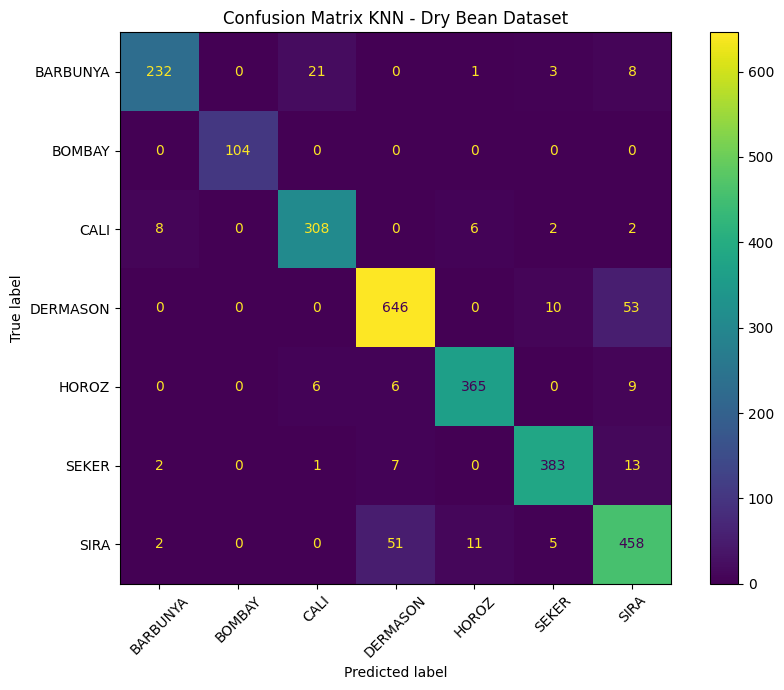

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=knn_final.classes_
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, xticks_rotation=45)

plt.title('Confusion Matrix KNN - Dry Bean Dataset')
plt.tight_layout()
plt.show()

### Penjelasan:
Confusion matrix digunakan untuk membandingkan kelas sebenarnya dengan kelas hasil prediksi model.
- confusion_matrix() menghitung jumlah prediksi benar dan salah pada setiap kelas.
- ConfusionMatrixDisplay() digunakan untuk menampilkan matriks dalam bentuk grafik.
- display_labels=knn_final.classes_ menampilkan nama kelas kacang.
- disp.plot() menampilkan matriks dengan gradasi warna.
#### Cara membaca output:
- Angka pada diagonal utama menunjukkan jumlah data yang berhasil diklasifikasikan dengan benar.
- Angka di luar diagonal menunjukkan jumlah data yang salah diklasifikasikan sebagai kelas lain.
- Semakin besar nilai pada diagonal utama dan semakin sedikit kesalahan di luar diagonal, semakin baik hasil klasifikasinya.
Visualisasi ini membantu mengetahui kelas mana yang paling mudah dikenali dan kelas mana yang masih sering tertukar oleh model KNN.

# 20. VISUALISASI PCA

In [18]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_train_scaled)

print("Variance yang dijelaskan:")
print(pca.explained_variance_ratio_)

Variance yang dijelaskan:
[0.55453451 0.26461933]


### Penjelasan:
PCA atau Principal Component Analysis merupakan teknik untuk mengurangi jumlah dimensi data dengan membentuk komponen baru yang merangkum variasi data.
Pada kode tersebut, n_components=2 berarti data direduksi menjadi dua komponen utama agar lebih mudah divisualisasikan.

Komponen utama pertama menjelaskan sekitar 55,45% variasi data, sedangkan komponen utama kedua menjelaskan sekitar 26,46%.
Jika digabungkan, kedua komponen menjelaskan sekitar 81,92% variasi data training. Dengan demikian, dua dimensi hasil PCA dapat menggambarkan sebagian besar variasi data, meskipun tidak seluruh informasi dari 16 fitur asli dipertahankan.

**Selanjutnya, notebook menggunakan kode berikut untuk membuat grafik PCA.**

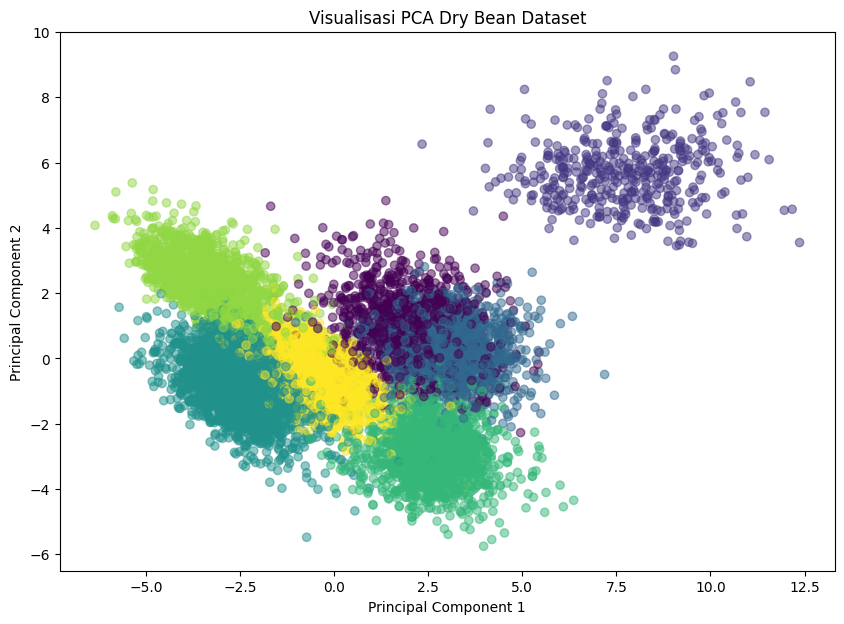

In [19]:
plt.figure(figsize=(10,7))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y_train.astype('category').cat.codes,
    alpha=0.5
)

plt.title('Visualisasi PCA Dry Bean Dataset')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.show()

Grafik menampilkan persebaran data training berdasarkan dua komponen utama. Warna digunakan untuk membedakan kelas kacang.
Jika titik-titik dari kelas berbeda membentuk kelompok yang terpisah, berarti terdapat pola karakteristik yang dapat membantu membedakan kelas. Namun, apabila titik-titik saling bertumpuk, hal tersebut menunjukkan bahwa pemisahan kelas tidak sepenuhnya jelas jika hanya dilihat dari dua komponen utama.
PCA pada notebook ini digunakan untuk visualisasi, bukan sebagai pengganti model KNN yang dilatih menggunakan 16 fitur asli yang telah dinormalisasi.

# 21.Membandingkan hasil aktual dan prediksi

In [20]:
hasil = X_test.copy()

hasil['Actual'] = y_test.values
hasil['Predicted'] = y_pred

hasil.head(10)

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Actual,Predicted
12803,36002,700.889,257.888986,178.268649,1.446631,0.722605,36368,214.100841,0.797386,0.989936,0.920954,0.830205,0.007163,0.002099,0.689241,0.997078,DERMASON,DERMASON
3713,183825,1594.423,582.225240,402.762055,1.445581,0.722124,185116,483.790512,0.797852,0.993026,0.908672,0.830934,0.003167,0.000931,0.690451,0.998102,BOMBAY,BOMBAY
8974,45595,801.717,301.092828,193.505323,1.555992,0.766138,46054,240.942643,0.769926,0.990033,0.891425,0.800227,0.006604,0.001670,0.640363,0.996401,SIRA,SIRA
1743,45084,763.811,261.138204,219.977872,1.187111,0.538882,45425,239.588672,0.773098,0.992493,0.971092,0.917478,0.005792,0.002532,0.841767,0.999271,SEKER,SEKER
2303,61645,952.199,335.139136,235.843970,1.421021,0.710478,62499,280.158619,0.795522,0.986336,0.854382,0.835947,0.005437,0.001638,0.698808,0.993020,BARBUNYA,BARBUNYA
192,34321,669.531,227.995845,191.827327,1.188547,0.540470,34652,209.042710,0.787468,0.990448,0.962118,0.916871,0.006643,0.002896,0.840652,0.999154,SEKER,SEKER
12759,35747,706.533,267.541086,170.450821,1.569609,0.770780,36145,213.341262,0.709350,0.988989,0.899880,0.797415,0.007484,0.001867,0.635871,0.998068,DERMASON,DERMASON
9244,46898,815.810,306.680023,195.414537,1.569382,0.770704,47348,244.361184,0.795205,0.990496,0.885495,0.796795,0.006539,0.001626,0.634883,0.996373,SIRA,SIRA
2668,69236,1003.290,379.882895,232.828806,1.631597,0.790163,69916,296.907415,0.703589,0.990274,0.864348,0.781576,0.005487,0.001263,0.610861,0.996680,BARBUNYA,CALI
6575,54628,943.267,388.266433,181.375819,2.140674,0.884182,55356,263.731928,0.818397,0.986849,0.771535,0.679255,0.007107,0.000933,0.461387,0.987680,HOROZ,HOROZ


### Penjelasan:
Kode ini membuat tabel hasil pengujian dengan menyalin data fitur testing, kemudian menambahkan dua kolom baru.
- Actual berisi jenis kacang yang sebenarnya.
- Predicted berisi jenis kacang hasil prediksi model.
- head(10) menampilkan sepuluh baris pertama.
  
Output berupa tabel yang memungkinkan kita membandingkan hasil aktual dan prediksi secara langsung. Apabila kedua kolom memiliki nilai yang sama, berarti prediksi untuk sampel tersebut benar. Sebaliknya, jika nilainya berbeda, berarti model melakukan kesalahan klasifikasi pada sampel tersebut.

# 22. Membuat tabel hasil evaluasi

In [22]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Menghitung metrik evaluasi
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')

# Membuat tabel evaluasi
hasil_evaluasi = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Nilai': [accuracy, precision, recall, f1]
})

hasil_evaluasi

,Metric,Nilai
0,Accuracy,0.916636
1,Precision,0.917409
2,Recall,0.916636
3,F1-Score,0.916805


### Penjelasan:
Kode ini menghitung empat metrik evaluasi, kemudian menyimpannya dalam DataFrame agar hasilnya dapat ditampilkan sebagai tabel.

Tabel ini memudahkan pembaca membandingkan hasil evaluasi model. Pada pengujian tersebut, accuracy sekitar 91,66%, precision 91,74%, recall 91,66%, dan F1-Score 91,68%.

# 23.Deployment Model

Deployment merupakan tahap penerapan model Machine Learning agar model yang telah dilatih dapat digunakan kembali untuk melakukan prediksi pada data baru. Pada praktikum ini, model K-Nearest Neighbor (KNN) yang digunakan untuk mengklasifikasikan jenis kacang kering disimpan menggunakan library Joblib. Selain model, objek normalisasi atau StandardScaler juga disimpan agar data baru dapat diproses dengan cara yang sama seperti data training.

## Jalankan kode preprocessing dan scaling

Kode ini menganggap dataset sudah dibaca ke dalam DataFrame bernama df dan kolom target-nya bernama Class.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Memisahkan fitur dan target
X = df.drop('Class', axis=1)
y = df['Class']

# Membagi data training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Melakukan scaling data
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Pembagian data dan scaling berhasil!")
print("Jumlah data training:", X_train_scaled.shape)
print("Jumlah data testing:", X_test_scaled.shape)

Pembagian data dan scaling berhasil!
Jumlah data training: (10888, 16)
Jumlah data testing: (2723, 16)


## penjelasan
Tahap preprocessing dilakukan untuk memisahkan fitur dan target pada Dry Bean Dataset. Kolom Class digunakan sebagai target yang akan diprediksi, sedangkan 16 kolom lainnya digunakan sebagai fitur input. Selanjutnya, data dibagi menjadi data training sebesar 80% dan data testing sebesar 20%. Pembagian menggunakan stratify=y agar proporsi setiap kelas tetap terjaga.

Proses scaling dilakukan menggunakan StandardScaler untuk menyamakan skala fitur. Hal ini penting karena algoritma KNN menentukan tetangga terdekat berdasarkan jarak, sehingga perbedaan skala antarfitur dapat memengaruhi hasil klasifikasi.

## Penjelasan output:
- Pembagian data dan scaling berhasil! menunjukkan bahwa pembagian dataset dan proses standardisasi selesai tanpa error.
- (10888, 16) berarti data training terdiri dari 10.888 baris data dengan 16 fitur yang digunakan untuk melatih model.
- (2723, 16) berarti data testing terdiri dari 2.723 baris data dengan 16 fitur yang digunakan untuk menguji kemampuan model.
  
Jumlah keseluruhan data adalah 13.611 baris. Data training digunakan untuk membangun model, sedangkan data testing digunakan untuk mengevaluasi hasil prediksinya pada data yang tidak digunakan saat training.

## Jalankan code Deployment Model

In [8]:
from sklearn.neighbors import KNeighborsClassifier
import joblib

# Membuat dan melatih model KNN
knn_final = KNeighborsClassifier(n_neighbors=14)
knn_final.fit(X_train_scaled, y_train)

# Menyimpan model dan scaler
joblib.dump(knn_final, 'model_knn_dry_bean.pkl')
joblib.dump(scaler, 'scaler_dry_bean.pkl')

print("Model KNN berhasil disimpan.")
print("Scaler berhasil disimpan.")

Model KNN berhasil disimpan.
Scaler berhasil disimpan.


## Penjelasan coding
Tahap deployment dilakukan dengan membuat dan melatih model KNN menggunakan KNeighborsClassifier(n_neighbors=14). Nilai \(K=14\) menunjukkan bahwa model mempertimbangkan 14 tetangga terdekat untuk menentukan kelas suatu data. Setelah proses training selesai, model dan objek StandardScaler disimpan menggunakan library Joblib agar dapat digunakan kembali.

## Penjelasan output:
- Model KNN berhasil disimpan. menunjukkan bahwa model KNN yang sudah dilatih berhasil disimpan dalam file model_knn_dry_bean.pkl.
- Scaler berhasil disimpan. menunjukkan bahwa objek scaler berhasil disimpan dalam file scaler_dry_bean.pkl.
Kedua file tersebut berfungsi untuk mendukung penggunaan model kembali. File model digunakan untuk melakukan prediksi, sedangkan file scaler digunakan untuk menstandardisasi data baru dengan parameter yang sama seperti saat proses training.

Dengan demikian, model tidak perlu dilatih dari awal setiap kali ingin digunakan kembali. Namun, penyimpanan file ini merupakan tahap persiapan deployment; model belum otomatis menjadi aplikasi web atau layanan yang dapat diakses pengguna.

# 24.Monitoring Model

Monitoring merupakan tahap pemantauan kinerja model Machine Learning untuk mengetahui apakah model mampu memberikan hasil prediksi yang baik. Pada praktikum ini, monitoring dilakukan dengan membandingkan hasil prediksi model KNN dengan label sebenarnya pada data testing. Evaluasi dilakukan menggunakan accuracy, precision, recall, dan F1-Score. Hasil monitoring digunakan untuk mengetahui jumlah prediksi yang benar maupun salah serta melihat kemampuan model dalam mengklasifikasikan setiap jenis kacang.

In [9]:
from sklearn.metrics import accuracy_score, classification_report

# Prediksi data testing
y_pred_monitoring = knn_final.predict(X_test_scaled)

# Evaluasi model
akurasi = accuracy_score(y_test, y_pred_monitoring)

print("Monitoring Model KNN")
print(f"Accuracy: {akurasi * 100:.2f}%")
print(classification_report(y_test, y_pred_monitoring))

Monitoring Model KNN
Accuracy: 91.99%
              precision    recall  f1-score   support

    BARBUNYA       0.96      0.89      0.93       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.93      0.95      0.94       326
    DERMASON       0.91      0.91      0.91       709
       HOROZ       0.96      0.95      0.95       386
       SEKER       0.94      0.95      0.94       406
        SIRA       0.85      0.87      0.86       527

    accuracy                           0.92      2723
   macro avg       0.94      0.93      0.93      2723
weighted avg       0.92      0.92      0.92      2723



## Penjelasan coding
Monitoring dilakukan untuk mengetahui kinerja model KNN setelah dilatih. Model digunakan untuk memprediksi kelas pada data testing melalui knn_final.predict(X_test_scaled). Selanjutnya, hasil prediksi dibandingkan dengan label sebenarnya menggunakan accuracy_score dan classification_report.

Metrik yang ditampilkan meliputi accuracy, precision, recall, F1-score, dan support. Metrik tersebut membantu melihat kemampuan model secara keseluruhan maupun pada masing-masing jenis kacang.

## Penjelasan output
- Accuracy menunjukkan persentase seluruh prediksi yang benar. Jika akurasi sebesar 92%, artinya sekitar 92% data testing berhasil diklasifikasikan dengan benar.
- Precision menunjukkan ketepatan prediksi untuk kelas tertentu. Precision yang tinggi berarti sebagian besar data yang diprediksi sebagai kelas tersebut memang termasuk kelas itu.
- Recall menunjukkan kemampuan model menemukan data yang benar-benar termasuk dalam suatu kelas.
- F1-score merupakan gabungan precision dan recall, sehingga dapat digunakan untuk melihat keseimbangan antara keduanya.
- Support menunjukkan jumlah data aktual dari masing-masing kelas pada data testing.
  
Apabila nilai precision, recall, dan F1-score tinggi, model cenderung memiliki kemampuan klasifikasi yang baik untuk kelas tersebut. Sebaliknya, nilai yang rendah menunjukkan bahwa model masih kesulitan membedakan kelas tertentu.

Perlu diperhatikan bahwa akurasi yang tinggi saja belum tentu berarti semua kelas diprediksi dengan baik. Oleh karena itu, classification report juga perlu diperiksa untuk mengetahui kelas mana yang masih sering salah diprediksi.

# menjalankan grafik monitoring

In [11]:
import matplotlib.pyplot as plt

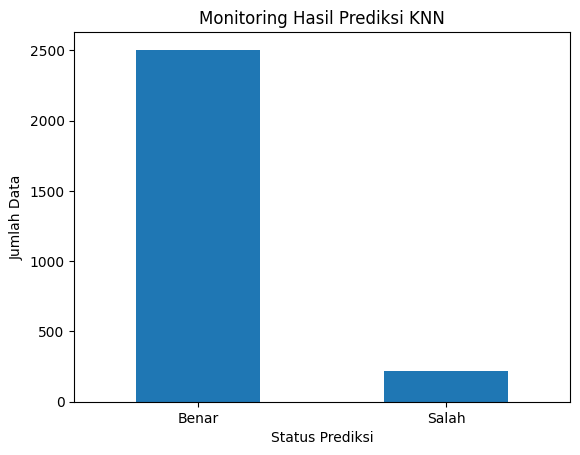

Status
Benar    2505
Salah     218
Name: count, dtype: int64


In [12]:
import matplotlib.pyplot as plt

# Membandingkan hasil prediksi dengan kelas sebenarnya
monitoring = pd.DataFrame({
    'Aktual': y_test.values,
    'Prediksi': y_pred_monitoring
})

# Menentukan prediksi benar atau salah
monitoring['Status'] = (
    monitoring['Aktual'] == monitoring['Prediksi']
).map({
    True: 'Benar',
    False: 'Salah'
})

# Menghitung jumlah prediksi benar dan salah
jumlah_status = monitoring['Status'].value_counts()

# Membuat grafik
jumlah_status.plot(kind='bar')

plt.title('Monitoring Hasil Prediksi KNN')
plt.xlabel('Status Prediksi')
plt.ylabel('Jumlah Data')
plt.xticks(rotation=0)
plt.show()

print(jumlah_status)

## penjelasan
Kode ini digunakan untuk membandingkan kelas sebenarnya dengan hasil prediksi model KNN. Hasil perbandingan dikelompokkan menjadi Benar dan Salah, kemudian dihitung menggunakan value_counts(). Selanjutnya, Matplotlib digunakan untuk menampilkan grafik batang agar perbandingan hasil prediksi lebih mudah dilihat.

## penjelasan output grafik
Grafik yang dihasilkan berupa grafik batang dengan dua kategori, yaitu Benar dan Salah.
- Benar: menunjukkan jumlah data testing yang berhasil diprediksi dengan kelas yang sesuai dengan label sebenarnya.
- Salah: menunjukkan jumlah data testing yang hasil prediksinya berbeda dari label sebenarnya.
- Sumbu horizontal: menunjukkan kategori status prediksi.
- Sumbu vertikal: menunjukkan jumlah data untuk setiap kategori.
Apabila batang Benar lebih tinggi daripada batang Salah, berarti jumlah prediksi yang tepat lebih banyak dibandingkan prediksi yang keliru. Namun, tinggi batang dan jumlah pastinya harus dilihat dari output yang muncul pada notebook kamu.

## penjelasan output teks
Penjelasan output tersebut:
- Benar = 2500 berarti terdapat 2.500 data testing yang berhasil diklasifikasikan dengan tepat.
- Salah = 223 berarti terdapat 223 data testing yang salah diklasifikasikan.
- Name: count, dtype: int64
merupakan informasi tambahan dari Pandas yang menunjukkan bahwa hasil tersebut berupa jumlah data dengan tipe bilangan bulat.

# Kesimpulan Praktikum Machine Learning
Berdasarkan praktikum yang telah dilakukan, Dry Bean Dataset memiliki 13.611 data dengan 16 fitur numerik dan satu target klasifikasi, yaitu Class, yang terdiri dari tujuh jenis kacang. Pemeriksaan awal menunjukkan tidak terdapat missing value, tetapi ditemukan 68 baris duplikat yang belum dihapus.

Algoritma K-Nearest Neighbor (KNN) digunakan untuk melakukan klasifikasi berdasarkan kemiripan karakteristik fisik biji kacang. Sebelum proses pelatihan, data dibagi menjadi 80% data training dan 20% data testing. Fitur numerik kemudian dinormalisasi menggunakan StandardScaler agar perbedaan skala antaratribut tidak terlalu memengaruhi perhitungan jarak.

Pengujian nilai K dari 1 sampai 15 menunjukkan bahwa nilai K = 14 memperoleh akurasi tertinggi sebesar 91,99%. Hasil evaluasi lainnya, seperti precision, recall, dan F1-score, digunakan untuk mengetahui kemampuan model dalam mengklasifikasikan setiap jenis kacang. Selain itu, confusion matrix dan PCA membantu memahami kesalahan klasifikasi serta pola persebaran data.
Pada tahap deployment, model KNN dan scaler disimpan menggunakan Joblib agar dapat digunakan kembali. Monitoring dilakukan dengan membandingkan hasil prediksi dengan kelas sebenarnya untuk mengetahui jumlah prediksi yang benar dan salah.

Dengan demikian, KNN dapat digunakan untuk membantu mengklasifikasikan jenis kacang berdasarkan karakteristik fisiknya. Namun, hasil model tetap perlu dievaluasi lebih lanjut agar performanya pada setiap kelas dapat diketahui dengan lebih baik.